In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score, brier_score_loss,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance

SEED = 42
DATA_PATH = Path('SHED 2025 CSV Raw.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('../upload/SHED 2025 CSV Raw.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError('Put SHED 2025 CSV Raw.csv beside the notebook or edit DATA_PATH.')
raw = pd.read_csv(DATA_PATH, low_memory=False)
print('Raw rows and columns:', raw.shape)
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__, '| sklearn:', sklearn.__version__)
print(raw['B2'].value_counts(dropna=False).to_string()) 



<class 'ModuleNotFoundError'>: No module named 'pandas'

In [ ]:
%pip install pandas numpy matplotlib scikit-learn


mambajs 0.21.4

Process pip requirements ...



Cannot install 'pandas' from PyPI because it is a binary built package that is not compatible with WASM environments. To resolve this issue, you can: 1) Try to install it from emscripten-forge instead: "!mamba install pandas" 2) If that doesn't work, it's probably that the package was not made WASM-compatible on emscripten-forge. You can either request or contribute a new recipe for that package in https://github.com/emscripten-forge/recipes 

In [2]:
!mamba install pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.251 seconds
  Name    Version  Build                Channel
-------------------------------------------------------------
+ pandas  3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
- pip     26.2.2   pyh145f28c_0         conda-forge


In [3]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score, brier_score_loss,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance

SEED = 42
DATA_PATH = Path('SHED 2025 CSV Raw.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('../upload/SHED 2025 CSV Raw.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError('Put SHED 2025 CSV Raw.csv beside the notebook or edit DATA_PATH.')
raw = pd.read_csv(DATA_PATH, low_memory=False)
print('Raw rows and columns:', raw.shape)
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__, '| sklearn:', sklearn.__version__)
print(raw['B2'].value_counts(dropna=False).to_string()) 



<class 'ModuleNotFoundError'>: No module named 'sklearn'

In [ ]:
%pip install scikit-learn

mambajs 0.21.4

Process pip requirements ...



Cannot install 'scikit-learn' from PyPI because it is a binary built package that is not compatible with WASM environments. To resolve this issue, you can: 1) Try to install it from emscripten-forge instead: "!mamba install scikit-learn" 2) If that doesn't work, it's probably that the package was not made WASM-compatible on emscripten-forge. You can either request or contribute a new recipe for that package in https://github.com/emscripten-forge/recipes 

In [4]:
!mamba install scikit-learn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 0.586 seconds
  Name                Version     Build                Channel
----------------------------------------------------------------------------
+ brotli-python       1.2.0       py313h8faef1e_3      emscripten-forge-4x
+ ca-certificates     2026.10.23  hbd8a1cb_0           conda-forge
+ certifi             2026.10.23  pyhd8ed1ab_3         conda-forge
+ charset-normalizer  3.5.1       pyhd8ed1ab_0         conda-forge
+ idna                3.20        pyh5ded981_0         conda-forge
+ joblib              1.6.0       py313h57e9779_0      emscripten-forge-4x
+ narwhals            2.28.0      pyh5ded981_0         conda-forge
+ pysocks             1.7.1       py313h1804a44_3      emscripten-forge-4x
+ requests            2.34.2      pyhcf101f3_0         conda-forge
+ scikit-learn   

In [5]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score, brier_score_loss,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance

SEED = 42
DATA_PATH = Path('SHED 2025 CSV Raw.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('../upload/SHED 2025 CSV Raw.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError('Put SHED 2025 CSV Raw.csv beside the notebook or edit DATA_PATH.')
raw = pd.read_csv(DATA_PATH, low_memory=False)
print('Raw rows and columns:', raw.shape)
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__, '| sklearn:', sklearn.__version__)
print(raw['B2'].value_counts(dropna=False).to_string()) 

Raw rows and columns: (12934, 815)
Python: 3.13.1 | pandas: 3.1.0 | sklearn: 1.9.1
B2
Doing okay                        5005
Living comfortably                4479
Just getting by                   2387
Finding it difficult to get by    1063


In [7]:
FEATURES = {
    'I40': 'Income bracket', 'I9': 'Income variability',
    'I20': 'Spending relative to income', 'EF1': 'Emergency savings response',
    'EF5C': 'Emergency expense response', 'BK1': 'Bank account response',
    'GH1': 'Housing tenure', 'ppage': 'Age', 'pphhsize': 'Household size',
    'ppkid017': 'Children in household', 'ppt18ov': 'Adults in household',
    'ppemploy': 'Employment status', 'ppmarit5': 'Marital status',
    'educ_4cat': 'Education category', 'ppreg4': 'Region'
}
NUMERIC = ['ppage', 'pphhsize', 'ppkid017', 'ppt18ov']
CATEGORICAL = [c for c in FEATURES if c not in NUMERIC]
assert set(FEATURES) | {'B2', 'shedid', 'weight'} <= set(raw.columns)
clean = raw.copy()
clean.columns = clean.columns.str.strip()
missing_labels = {'', 'refused', 'not asked', 'not applicable', 'skipped',
                  "don't know", 'dont know', 'no response', 'nan',
                  '-1', '-2', '-3', '-4', '-5', '-7', '-8', '-9', '-99'}
for col in clean.select_dtypes(include=['object', 'str']):
    s = clean[col].str.strip().str.replace(r'\s+', ' ', regex=True)
    clean[col] = s.mask(s.str.casefold().isin(missing_labels))
before = len(clean)
clean = clean.drop_duplicates()
print('Exact duplicate rows removed:', before - len(clean))
if clean['shedid'].duplicated().any():
    raise ValueError('Repeated respondent IDs need review before splitting.')
target_map = {'Just getting by': 1, 'Finding it difficult to get by': 1,
              'Doing okay': 0, 'Living comfortably': 0}
y_all = clean['B2'].map(target_map)
print('Missing/unrecognized targets excluded:', int(y_all.isna().sum()))
data = clean.loc[y_all.notna(), list(FEATURES)].copy()
y = y_all.loc[data.index].astype(int).rename('vulnerable')
for col in NUMERIC:
    data[col] = pd.to_numeric(data[col], errors='coerce')
    data.loc[data[col] < 0, col] = np.nan
data.loc[~data['ppage'].between(18, 120), 'ppage'] = np.nan
for col in CATEGORICAL:
    data[col] = data[col].astype(object).where(data[col].notna(), np.nan)
audit = pd.DataFrame({'description': pd.Series(FEATURES),
    'missing_n': data.isna().sum(), 'missing_pct': data.isna().mean().mul(100),
    'distinct_nonmissing': data.nunique()})
print(audit.round(2).to_string())
print('Modeling rows:', len(data), '| Vulnerable fraction:', round(y.mean(), 4))


Exact duplicate rows removed: 0
Missing/unrecognized targets excluded: 0
                           description  missing_n  missing_pct  distinct_nonmissing
I40                     Income bracket          0          0.0                   15
I9                  Income variability          0          0.0                    3
I20        Spending relative to income          0          0.0                    3
EF1         Emergency savings response          0          0.0                    2
EF5C        Emergency expense response          0          0.0                    2
BK1              Bank account response          0          0.0                    2
GH1                     Housing tenure          0          0.0                    4
ppage                              Age          0          0.0                   81
pphhsize                Household size          0          0.0                   12
ppkid017         Children in household          0          0.0                   10
ppt

Reserve 20% as the untouched stratified test set. Median imputation for numeric features and one-hot encoding for categorical features are fit inside cross-validation, using training folds only. Trees do not need scaling. Missing categorical values receive a separate category. Unknown test categories are ignored safely.

This is a respondent-level educational model. Primary fitting and evaluation are unweighted. A secondary weighted test table uses the supplied weight column; it is a sensitivity check, not a design-based population estimate with survey uncertainty.

In [8]:
#split before preprocessing 
X_train, X_test, y_train, y_test = train_test_split(
    data, y, test_size=0.20, random_state=SEED, stratify=y)
numeric_pipe = Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True))])
categorical_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value='Missing or not asked')),
    ('encode', OneHotEncoder(handle_unknown='ignore'))])
preprocess = ColumnTransformer([
    ('numeric', numeric_pipe, NUMERIC),
    ('categorical', categorical_pipe, CATEGORICAL)])
pipeline = Pipeline([('preprocess', preprocess),
    ('tree', DecisionTreeClassifier(random_state=SEED))])
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Train/test positive rates:', y_train.mean().round(4), y_test.mean().round(4))
assert set(X_train.index).isdisjoint(X_test.index)
assert 'B2' not in data and 'atleast_okay' not in data


Train: (10347, 15) | Test: (2587, 15)
Train/test positive rates: 0.2667 0.2667


Tune the Decision Tree: Search depth, minimum leaf size, and class weighting with five training-only stratified folds. Select by average precision (often called PR AUC; this uses sklearn’s non-interpolated average precision). Larger values are better. Regularization limits overfitting. The test set never selects hyperparameters or the threshold.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
search = GridSearchCV(pipeline, {
    'tree__max_depth': [3, 5, 8],
    'tree__min_samples_leaf': [30, 100],
    'tree__class_weight': [None, 'balanced']},
    scoring='average_precision', cv=cv, n_jobs=-1, return_train_score=True)
search.fit(X_train, y_train)
best_model = search.best_estimator_
print('Best parameters:', search.best_params_)
print('Best training CV average precision:', round(search.best_score_, 4))
cv_table = pd.DataFrame(search.cv_results_).sort_values('rank_test_score')
print(cv_table[['params', 'mean_train_score', 'mean_test_score', 'std_test_score']].head(6).to_string(index=False))


Best parameters: {'tree__class_weight': 'balanced', 'tree__max_depth': 8, 'tree__min_samples_leaf': 100}
Best training CV average precision: 0.6542
                                                                                 params  mean_train_score  mean_test_score  std_test_score
{'tree__class_weight': 'balanced', 'tree__max_depth': 8, 'tree__min_samples_leaf': 100}          0.682893         0.654196        0.020089
 {'tree__class_weight': 'balanced', 'tree__max_depth': 8, 'tree__min_samples_leaf': 30}          0.696725         0.653090        0.018273
      {'tree__class_weight': None, 'tree__max_depth': 8, 'tree__min_samples_leaf': 100}          0.682381         0.651583        0.017604
{'tree__class_weight': 'balanced', 'tree__max_depth': 5, 'tree__min_samples_leaf': 100}          0.659968         0.647112        0.011579
       {'tree__class_weight': None, 'tree__max_depth': 8, 'tree__min_samples_leaf': 30}          0.715337         0.646603        0.011128
      {'tree__clas

Evaluate once on held-out respondents: Class 1 means vulnerable. Report a prevalence baseline as well as accuracy, balanced accuracy, precision, recall, F1, ROC AUC, average precision, and Brier score. Lower Brier is better; the others are higher-is-better. Use a fixed 0.50 probability threshold. A higher recall can come with more false positives; class weighting can also affect probability calibration.

               accuracy  balanced_accuracy  precision  recall      F1  ROC_AUC  average_precision   Brier
Baseline         0.7333             0.5000     0.0000  0.0000  0.0000   0.5000             0.2667  0.1956
Decision tree    0.7681             0.7819     0.5437  0.8116  0.6512   0.8577             0.6735  0.1555

Train average precision: 0.6846

                           precision    recall  f1-score   support

Doing okay / comfortable       0.92      0.75      0.83      1897
              Vulnerable       0.54      0.81      0.65       690

                accuracy                           0.77      2587
               macro avg       0.73      0.78      0.74      2587
            weighted avg       0.82      0.77      0.78      2587

Weighted test sensitivity check:
               accuracy  balanced_accuracy  precision  recall      F1  ROC_AUC  average_precision   Brier
Baseline         0.7358             0.5000     0.0000  0.0000  0.0000   0.5000             0.2642  0.1944
Dec

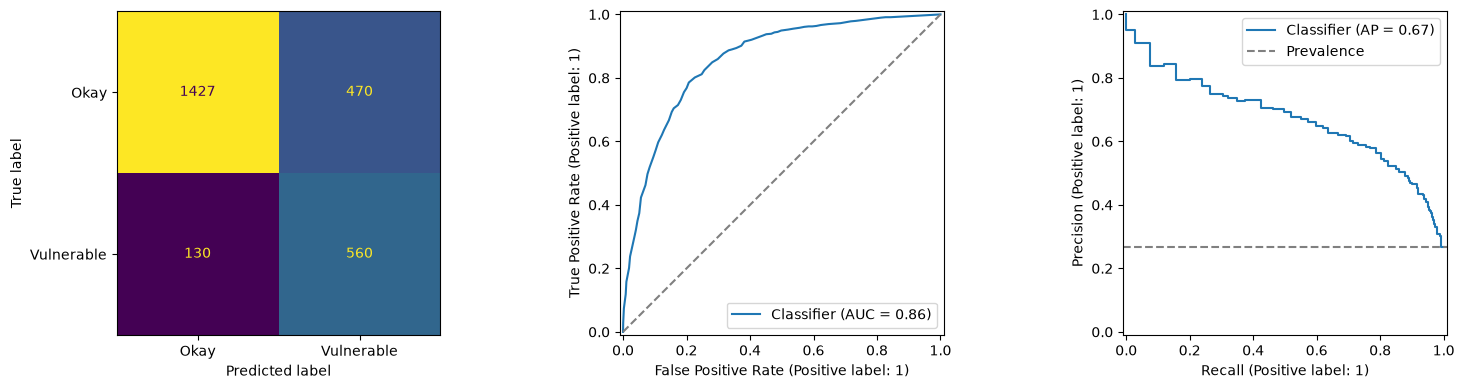

In [10]:
baseline = DummyClassifier(strategy='prior').fit(X_train, y_train)
def evaluate(y_true, prob, weights=None):
    pred = (prob >= 0.5).astype(int)
    return {
        'accuracy': accuracy_score(y_true, pred, sample_weight=weights),
        'balanced_accuracy': balanced_accuracy_score(y_true, pred, sample_weight=weights),
        'precision': precision_score(y_true, pred, sample_weight=weights, zero_division=0),
        'recall': recall_score(y_true, pred, sample_weight=weights, zero_division=0),
        'F1': f1_score(y_true, pred, sample_weight=weights, zero_division=0),
        'ROC_AUC': roc_auc_score(y_true, prob, sample_weight=weights),
        'average_precision': average_precision_score(y_true, prob, sample_weight=weights),
        'Brier': brier_score_loss(y_true, prob, sample_weight=weights)}
test_prob = best_model.predict_proba(X_test)[:, 1]
baseline_prob = baseline.predict_proba(X_test)[:, 1]
results = pd.DataFrame({'Baseline': evaluate(y_test, baseline_prob),
                        'Decision tree': evaluate(y_test, test_prob)}).T
print(results.round(4).to_string())
print('\nTrain average precision:', round(average_precision_score(
    y_train, best_model.predict_proba(X_train)[:, 1]), 4))
print('\n', classification_report(y_test, (test_prob >= .5).astype(int),
    target_names=['Doing okay / comfortable', 'Vulnerable'], zero_division=0))
w_test = pd.to_numeric(clean.loc[X_test.index, 'weight'], errors='coerce')
if w_test.notna().all() and (w_test > 0).all():
    print('Weighted test sensitivity check:')
    print(pd.DataFrame({'Baseline': evaluate(y_test, baseline_prob, w_test),
        'Decision tree': evaluate(y_test, test_prob, w_test)}).T.round(4).to_string())
else:
    print('Weighted sensitivity check omitted: invalid survey weights.')
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(y_test, (test_prob >= .5).astype(int),
    display_labels=['Okay', 'Vulnerable'], ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, test_prob, ax=axes[1])
axes[1].plot([0, 1], [0, 1], '--', color='gray')
PrecisionRecallDisplay.from_predictions(y_test, test_prob, ax=axes[2])
axes[2].axhline(y_test.mean(), linestyle='--', color='gray', label='Prevalence')
axes[2].legend()
plt.tight_layout()
plt.show()


Explaining Model: Permutation importance measures the decrease in test average precision when one original feature is shuffled. It avoids splitting a categorical feature’s importance across one-hot columns. Correlated features can hide each other’s importance. Importance is not a causal effect, and this exploratory test inspection must not be used to retune the model on this test set.

  feature  mean_AP_drop  std_AP_drop                 description
      EF1        0.1556       0.0120  Emergency savings response
      I20        0.1249       0.0107 Spending relative to income
     EF5C        0.0341       0.0050  Emergency expense response
      GH1        0.0337       0.0060              Housing tenure
educ_4cat        0.0120       0.0024          Education category
    ppage        0.0091       0.0032                         Age
      I40        0.0073       0.0017              Income bracket
 ppmarit5        0.0037       0.0011              Marital status
 ppemploy        0.0033       0.0018           Employment status
       I9        0.0011       0.0034          Income variability
 pphhsize        0.0001       0.0012              Household size
   ppreg4        0.0001       0.0006                      Region
      BK1        0.0000       0.0000       Bank account response
 ppkid017        0.0000       0.0000       Children in household
  ppt18ov       -0.0000  

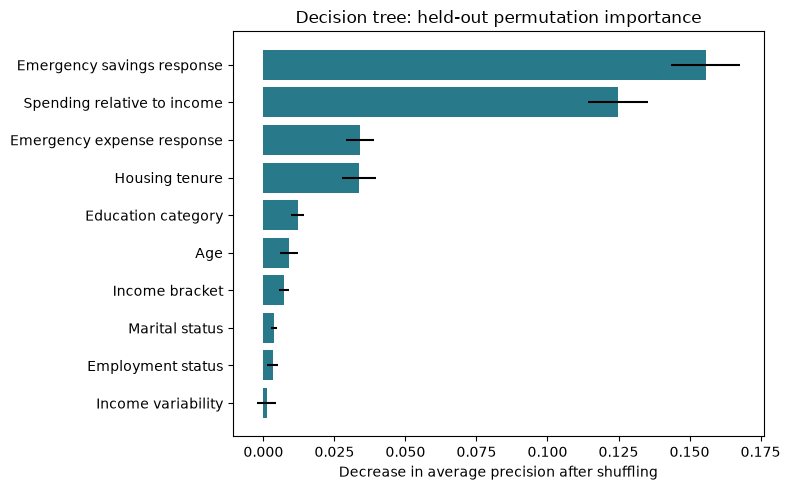

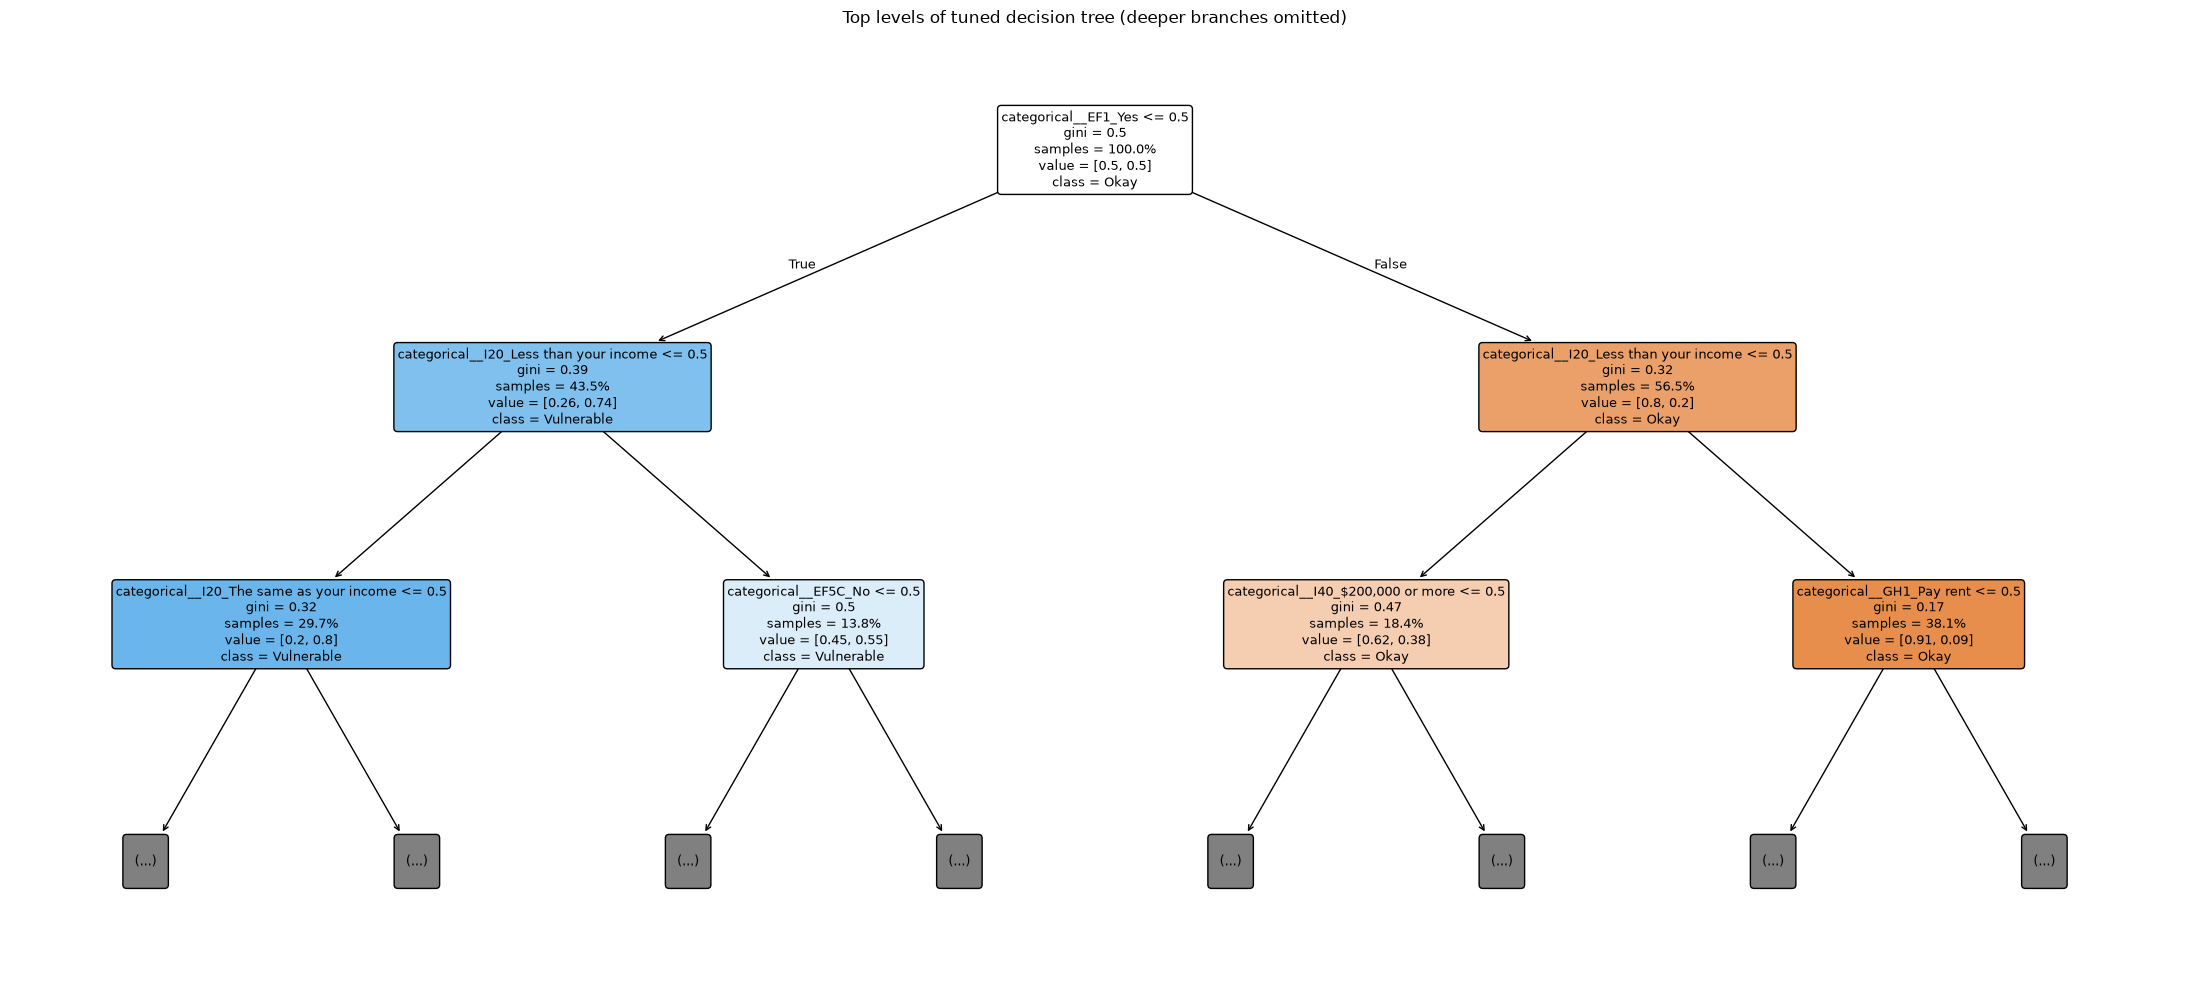

In [11]:
importance = permutation_importance(best_model, X_test, y_test,
    scoring='average_precision', n_repeats=10, random_state=SEED, n_jobs=-1)
importance_table = pd.DataFrame({'feature': X_test.columns,
    'mean_AP_drop': importance.importances_mean,
    'std_AP_drop': importance.importances_std}).sort_values('mean_AP_drop', ascending=False)
importance_table['description'] = importance_table['feature'].map(FEATURES)
print(importance_table.round(4).to_string(index=False))
top = importance_table.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top['description'], top['mean_AP_drop'], xerr=top['std_AP_drop'], color='#287a8b')
ax.set_xlabel('Decrease in average precision after shuffling')
ax.set_title('Decision tree: held-out permutation importance')
plt.tight_layout()
plt.show()

names = best_model.named_steps['preprocess'].get_feature_names_out()
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(best_model.named_steps['tree'], feature_names=names,
    class_names=['Okay', 'Vulnerable'], max_depth=2, filled=True,
    rounded=True, proportion=True, precision=2, fontsize=9, ax=ax)
ax.set_title('Top levels of tuned decision tree (deeper branches omitted)')
plt.tight_layout()
plt.show()


Read Findings: The table above compares the models using test data they did not train on. The baseline model always predicts the more common group, so it can have high accuracy while missing every financially vulnerable respondent. To better understand the decision tree’s performance, look at recall, precision, average precision, and Brier score together. If the model performs much better on training data than test data, it may be overfitting, meaning it learned patterns that do not work as well on new data. Weighted and unweighted results may differ because survey weights give some respondents more influence to better represent the population.

Limitations: B2 measures how people describe their own financial situation. Missing answers, skipped questions, and values filled in before we received the data can affect the results. This notebook does additional cleaning, but it cannot recover the original missing answers. Because the predictors and outcome describe the same period, the model identifies current patterns rather than predicting future financial problems. Its performance may also vary across demographic groups, so we cannot assume it works equally well for everyone. It should not be used to decide whether someone qualifies for financial services.

To predict a different outcome, update the target variable and check that the inputs do not accidentally reveal the answer. Before adding more variables, review the survey questionnaire or codebook to understand what they mean. Future improvements could include testing the model on another survey year, comparing its performance across groups, and checking whether its predicted probabilities match actual outcomes. Any cutoff used to flag respondents should be chosen using separate validation data.

To save the cleaned modeling data and cleaning summary, change `EXPORT` to `True` in the next cell. Missing numerical values will still appear in the exported table because the model fills them in during processing using information from the training data. The preprocessing steps are included in `best_model`, so it can also make predictions for new respondents when given the same input columns.

In [12]:
EXPORT = False
if EXPORT:
    output_dir = Path('model_outputs')
    output_dir.mkdir(exist_ok=True)
    data.assign(vulnerable=y).to_csv(output_dir / 'cleaned_modeling_data.csv', index=False)
    audit.to_csv(output_dir / 'cleaning_audit.csv')
    results.to_csv(output_dir / 'test_metrics.csv')
    importance_table.to_csv(output_dir / 'feature_importance.csv', index=False)
    print('Saved modeling data, audit, metrics, and importance to', output_dir)
